# Backtest d'une stratégie SMA Crossover sur le CAC 40

**Question :** une stratégie de moyennes mobiles fait-elle mieux que d'acheter et garder le CAC 40 (buy & hold), en gain et en risque ?

**Plan :**
1. Construire un backtest honnête .
2. Vérifier si elle prend moins de risque
3. Conclure.

## Partie 1 : construction du backtest
On télécharge les prix du CAC 40 depuis 2014 et on calcule les rendements journaliers.

In [2]:
import yfinance as yf
df = yf.download('^FCHI', start='2014-01-01', auto_adjust=True)
df.head()
   

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^FCHI,^FCHI,^FCHI,^FCHI,^FCHI
Date,,,,,
2014-01-02,4227.279785,4312.589844,4226.660156,4307.399902,86282800
2014-01-03,4247.649902,4258.890137,4228.850098,4238.759766,59137700
2014-01-06,4227.540039,4261.339844,4221.709961,4242.270020,68734800
2014-01-07,4262.680176,4266.959961,4215.589844,4231.500000,102867800
2014-01-08,4260.959961,4272.069824,4245.560059,4269.459961,100876000


Date
2014-01-02    4227.279785
2014-01-03    4247.649902
2014-01-06    4227.540039
2014-01-07    4262.680176
2014-01-08    4260.959961
Name: ^FCHI, dtype: float64
Nombre de jours : 3283


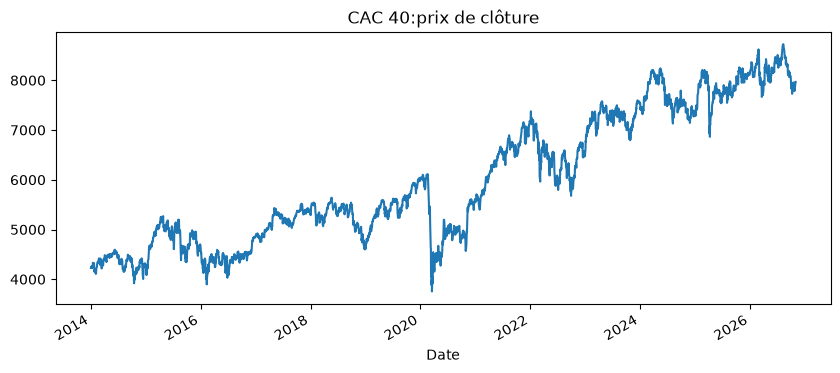

In [3]:
import matplotlib.pyplot as plt

prices = df['Close'].squeeze().dropna()
print(prices.head())
print("Nombre de jours :", len(prices))

prices.plot(title="CAC 40:prix de clôture", figsize=(10, 4))
plt.show()

Date
2014-01-03    0.004819
2014-01-06   -0.004734
2014-01-07    0.008312
2014-01-08   -0.000404
2014-01-09   -0.008407
Name: ^FCHI, dtype: float64
Rendement moyen Par jour : 0.0002581742308282166
Volatilité par jour : 0.0113716539030172


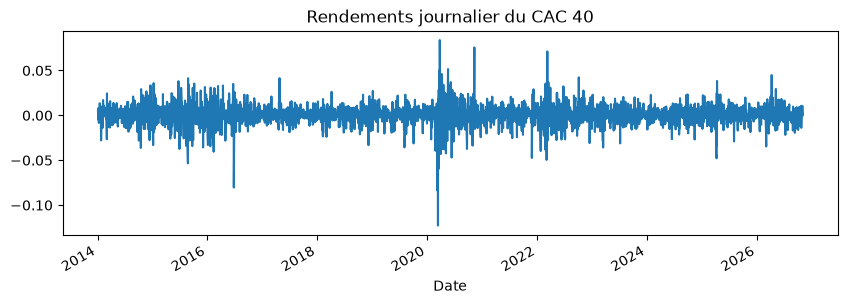

In [4]:
returns = prices.pct_change().dropna()

print(returns.head())
print("Rendement moyen Par jour :", returns.mean())
print("Volatilité par jour :", returns.std())

returns.plot(title="Rendements journalier du CAC 40", figsize=(10, 3))
plt.show()

### La stratégie
On compare ici deux moyennes du prix : 20 jours (tendance récente) et 100 jours (tendance de fond).
Si la moyenne 20 jours est au-dessus de la 100 jours, on est investi (1). Sinon, on sort du marché (0).


In [5]:
short_window = 20
long_window = 100

sma_short = prices.rolling(short_window).mean()
sma_long = prices.rolling(long_window).mean()

print(sma_short.tail())
print(sma_long.tail())
print(sma_long.head())

Date
2026-10-26    7861.445972
2026-10-27    7854.009473
2026-10-28    7850.131982
2026-10-29    7856.866479
2026-10-30    7860.477979
Name: ^FCHI, dtype: float64
Date
2026-10-26    8272.639780
2026-10-27    8269.476885
2026-10-28    8266.728184
2026-10-29    8264.420186
2026-10-30    8260.605684
Name: ^FCHI, dtype: float64
Date
2014-01-02   NaN
2014-01-03   NaN
2014-01-06   NaN
2014-01-07   NaN
2014-01-08   NaN
Name: ^FCHI, dtype: float64


In [6]:
signal = (sma_short > sma_long).astype(int) # ici les 99 valeurs du debut de sma_long sont NaN donc comparer avec eux donne False

print(signal.tail(10))
print(signal.value_counts())

Date
2026-10-19    0
2026-10-20    0
2026-10-21    0
2026-10-22    0
2026-10-23    0
2026-10-26    0
2026-10-27    0
2026-10-28    0
2026-10-29    0
2026-10-30    0
Name: ^FCHI, dtype: int64
^FCHI
1    1963
0    1320
Name: count, dtype: int64



### Règle anti-triche
Le signal est calculé avec le prix de clôture, connu seulement le soir. On n'agit donc que le lendemain : la position du jour est le signal de la veille.

In [7]:
import pandas as pd

position = signal.shift(1).fillna(0)

print(pd.DataFrame({"signal": signal, "Position": position}).tail(40))

            signal  Position
Date                        
2026-09-07       1       1.0
2026-09-08       1       1.0
2026-09-09       1       1.0
2026-09-10       1       1.0
2026-09-11       1       1.0
2026-09-14       1       1.0
2026-09-15       0       1.0
2026-09-16       0       0.0
2026-09-17       0       0.0
2026-09-18       0       0.0
2026-09-21       0       0.0
2026-09-22       0       0.0
2026-09-23       0       0.0
2026-09-24       0       0.0
2026-09-25       0       0.0
2026-09-28       0       0.0
2026-09-29       0       0.0
2026-09-30       0       0.0
2026-10-01       0       0.0
2026-10-02       0       0.0
2026-10-05       0       0.0
2026-10-06       0       0.0
2026-10-07       0       0.0
2026-10-08       0       0.0
2026-10-09       0       0.0
2026-10-12       0       0.0
2026-10-13       0       0.0
2026-10-14       0       0.0
2026-10-15       0       0.0
2026-10-16       0       0.0
2026-10-19       0       0.0
2026-10-20       0       0.0
2026-10-21    

### Résultat sans frais
On calcule ce que devient 1 € investi avec la stratégie, et on le compare au buy & hold.

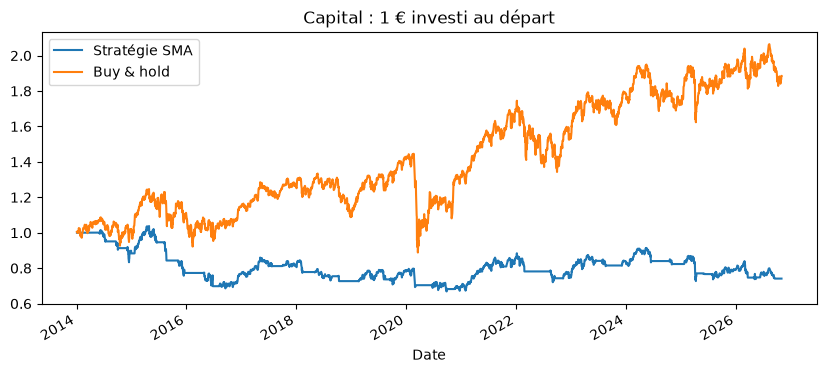

Capital final stratégie : 0.741093545976718
Capital final buy & hold : 1.8852359737008575


In [8]:
strategy_returns = (position * returns).dropna() #les 100 premiers jours restent, avec un rendement de 0 (stratégie bloquée)r 
capital_strategy = (1 + strategy_returns).cumprod()
capital_buyhold = (1 + returns.loc[strategy_returns.index]).cumprod() # loc> pour quil commence en meme temp que la stratgie
plt.figure(figsize=(10, 4))
capital_strategy.plot(label="Stratégie SMA")
capital_buyhold.plot(label="Buy & hold")
plt.legend()
plt.title("Capital : 1 € investi au départ")
plt.show()
print("Capital final stratégie :", capital_strategy.iloc[-1])
print("Capital final buy & hold :", capital_buyhold.iloc[-1])

Au début, la courbe de la stratégie est plate : pendant les 100 premiers jours, la moyenne 100 jours n'existe pas encore, donc la stratégie ne peut pas investir et son capital reste à 1 €. Le buy & hold, lui, est déjà investi. On corrige ce décalage plus bas, en faisant démarrer les deux courbes le même jour.

In [9]:
nb_trades = position.diff().abs().sum()
part_investi = position.mean()

print("Nombre de changements de position :", nb_trades)
print("Part du temps investi :", part_investi)

Nombre de changements de position : 58.0
Part du temps investi : 0.5979287237282973


- 58 changements de position sur la période, soit environ 29 achats et 29 ventes, ou 5 par an en moyenne. Chaque position est donc gardée plusieurs mois : c'est une stratégie de suivi de tendance, pas de trading au jour le jour.
- La stratégie est investie 60 % du temps et reste hors du marché les 40 % restants.

**Ce que ces chiffres impliquent :**
- Les coûts : chaque changement de position coûte des frais. Avec 58 changements à 0,1 %, les frais retirent environ 6 % au capital sur la période.
- Le risque : les jours hors du marché, le rendement est nul. La volatilité de la stratégie est donc mécaniquement plus faible que celle du CAC 40, sans qu'elle soit vraiment mieux protégée.
- gains manqués : être hors du marché 40 % du temps fait aussi rater une partie des hausses, en particulier les rebonds qui suivent les crises.

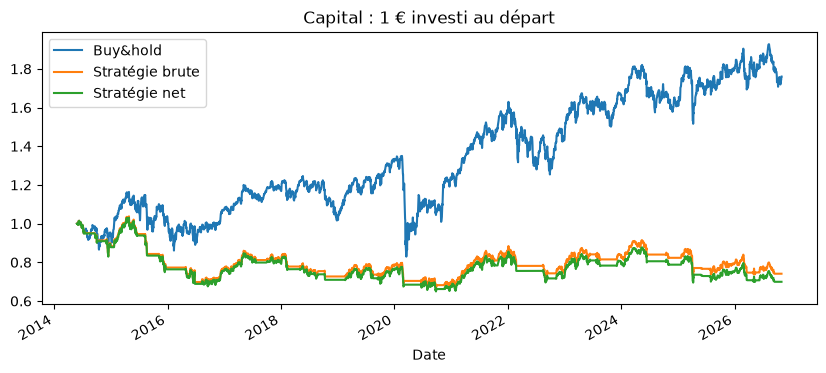

Capital final brut : 0.741093545976718
Capital final net : 0.699332071629148


In [18]:
cost = 0.001  # 0,1% par changementde position

change = position.diff().abs().fillna(0)
net_returns = strategy_returns - change.loc[strategy_returns.index] * cost

capital_net = (1 + net_returns).cumprod()

plt.figure(figsize=(10, 4))
capital_buyhold.plot(label="Buy&hold")
capital_strategy.plot(label="Stratégie brute")
capital_net.plot(label="Stratégie net")
plt.legend()
plt.title("Capital : 1 € investi au départ")
plt.show()

print("Capital final brut :", capital_strategy.iloc[-1])
print("Capital final net :", capital_net.iloc[-1])

Les coûts de transaction sont fixés à 0,1 % par changement de position. C’est une hypothèse d’ordre de grandeur (frais de courtage, spread et slippage). Même sans aucun coût, la stratégie reste moins bonne que le buy & hold, donc la conclusion ne dépend pas de ce choix

### Comparaison équitable
La moyenne 100 jours n'existe qu'à partir du 100eme jour : avant, la stratégie ne peut rien décider. On fait donc démarrer les deux courbes le même jour.

In [19]:
start = sma_long.dropna().index[0]

strategy_returns = strategy_returns.loc[strategy_returns.index > start]
net_returns = net_returns.loc[net_returns.index > start]

capital_strategy = (1 + strategy_returns).cumprod()
capital_net = (1 + net_returns).cumprod()
capital_buyhold = (1 + returns.loc[strategy_returns.index]).cumprod() # commennce en meme temps que la strategie

print("La comparaison commence le :", strategy_returns.index[0])


La comparaison commence le : 2014-05-27 00:00:00



## Partie 2 : la stratégie est-elle moins risquée ?
La stratégie gagne moins que le buy & hold. On vérifie si, en échange, elle prend moins de risque ou protège mieux pendant les crises.

In [20]:
def metrics(r):
    capital = 1* (1 + r).cumprod()
    n = len(r)
    ann_return = capital.iloc[-1] ** (252 / n) - 1
    ann_vol = r.std() * (252 ** 0.5)
    sharpe = r.mean() / r.std() * (252 ** 0.5)
    max_dd = (capital / capital.cummax() - 1).min()
    return pd.Series({
        "Rendement annuel": ann_return,
        "Volatilité annuelle": ann_vol,
        "Sharpe": sharpe,
        "Max Drawdown": max_dd,
    })

table = pd.DataFrame({
    "Buy & hold": metrics(returns.loc[strategy_returns.index]),
    "Stratégie brute": metrics(strategy_returns),
    "Stratégie nette": metrics(net_returns),
})
print(table.round(3))

                     Buy & hold  Stratégie brute  Stratégie nette
Rendement annuel          0.046           -0.023           -0.028
Volatilité annuelle       0.182            0.119            0.119
Sharpe                    0.338           -0.139           -0.178
Max Drawdown             -0.386           -0.356           -0.370


La stratégie perd de l'argent (-2,8 % par an, Sharpe -0,18), alors que le buy & hold gagne +4,6 % par an (Sharpe 0,34). Sa volatilité est plus faible, mais seulement parce qu'elle est hors du marché 40 % du temps. Sa pire chute (-37 %) est presque la même que celle du buy & hold.

### LA COURBE DU DRAWDOWN

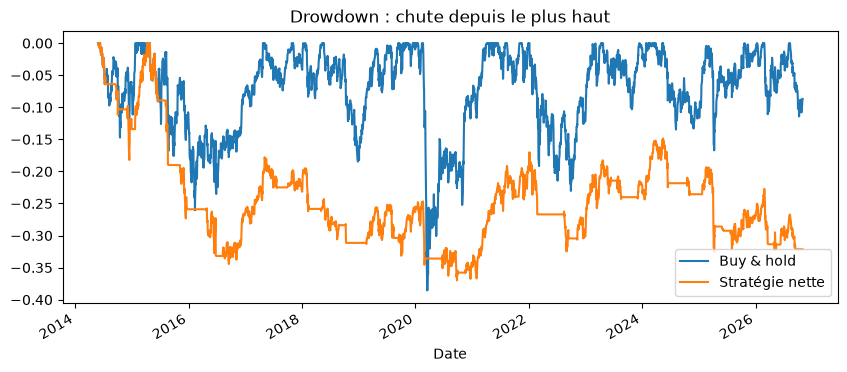

In [21]:
dd_buyhold = capital_buyhold / capital_buyhold.cummax() - 1
dd_strategy = capital_net / capital_net.cummax() - 1

plt.figure(figsize=(10, 4))
dd_buyhold.plot(label="Buy & hold")
dd_strategy.plot(label="Stratégie nette")
plt.legend()
plt.title("Drowdown : chute depuis le plus haut")
plt.show()

### Analyse du drawdown

Le drawdown mesure, chaque jour, la chute du capital depuis son plus haut niveau atteint. À 0, le capital est à son record ; plus la courbe descend, plus la perte depuis ce record est forte.

**Buy & hold**
- Le CAC 40 subit plusieurs chutes importantes : 2015-2016 (environ -26 %), fin 2018 (environ -18 %), mars 2020 avec la crise du Covid (-38,6 %, la pire chute de la période) et 2022 (environ -23 %).
- Après chaque chute, la courbe revient à 0 : le capital retrouve son plus haut. Par exemple, la chute du Covid est effacée en environ un an.

**Stratégie net**
- La stratégie n'a jamais retrouvé son plus haut de 2015 : elle reste sous zéro pendant plus de dix ans, entre -15 % et -37 %.
- Les paliers horizontaux correspondent aux périodes où la stratégie est hors du marché : le capital ne bouge plus.
- Pendant la crise de 2020, la stratégie subit le début de la chute (fin février), sort du marché pendant le pire du krach, puis rate le rebond qui suit.

**Conclusion**
Le Max Drawdown des deux approches est proche (-38,6 % contre -37,0 %), mais la courbe montre une différence majeure : le buy & hold récupère après chaque crise, alors que la stratégie reste durablement en perte. Un investisseur dans cette stratégie aurait passé plus de dix ans sans jamais revoir son meilleur niveau. La stratégie ne remplit donc pas son rôle de protection pendant les crises.

### LE STRESS TEST

Une stratégie peut avoir l’air bonne « en moyenne » et s’effondrer les jours de panique. Le stress test regarde seulement les jours extrêmes pour voir comment la stratégie se comporte quand tout va très mal (ou très bien).
Ce qu’on a fait
- On a pris les 10 pires jours du CAC 40 depuis 2014.
- Pour chacun, on a regardé : la stratégie était-elle investie ce jour-là (position = 1) ou sortie (position = 0) ?
- On a fait pareil avec les 10 meilleurs jours.

In [22]:
bh_returns = returns.loc[capital_buyhold.index]
pires = bh_returns.nsmallest(10)

stress = pd.DataFrame()
stress["CAC 40 (%)"] = (pires * 100).round(2)
stress["Position"] = position.loc[pires.index]
stress["Stratégie nette (%)"] = (net_returns.loc[pires.index] * 100).round(2)

print(stress)
print("Jours où la stratégie était investie :", int(stress["Position"].sum()), "sur 10")

            CAC 40 (%)  Position  Stratégie nette (%)
Date                                                 
2020-03-12      -12.28       0.0                -0.00
2020-03-09       -8.39       0.0                -0.00
2016-06-24       -8.04       1.0                -8.04
2020-03-18       -5.94       0.0                -0.00
2020-03-16       -5.75       0.0                -0.00
2015-08-24       -5.35       0.0                -0.10
2022-03-04       -4.97       0.0                -0.00
2025-04-07       -4.78       1.0                -4.78
2021-11-26       -4.75       1.0                -4.75
2020-06-11       -4.71       0.0                -0.00
Jours où la stratégie était investie : 3 sur 10



**Remarque :** le 24 août 2015, la stratégie n'était pas exposée (position = 0), mais elle affiche une perte de 0,10 %. Cela correspond aux frais de transaction : ce jour-là, elle a vendu sa position, et chaque changement de position coûte 0,1 %. Elle a ainsi évité une baisse de 5,35 % pour un coût de seulement 0,1 %.

LES MEILLEURS JOURS

In [23]:
meilleurs = bh_returns.nlargest(10)

best = pd.DataFrame()
best["CAC 40 (%)"] = (meilleurs * 100).round(2)
best["Position"] = position.loc[meilleurs.index]
best["Stratégie nette (%)"] = (net_returns.loc[meilleurs.index] * 100).round(2)

print(best)
print("Jours où la stratégie était investie :", int(best["Position"].sum()), "sur 10")

            CAC 40 (%)  Position  Stratégie nette (%)
Date                                                 
2020-03-24        8.39       0.0                 0.00
2020-11-09        7.57       0.0                 0.00
2022-03-09        7.13       0.0                 0.00
2020-05-18        5.16       0.0                 0.00
2020-03-20        5.01       0.0                 0.00
2020-04-06        4.61       0.0                 0.00
2026-04-08        4.49       0.0                 0.00
2020-03-25        4.47       0.0                 0.00
2022-10-04        4.24       0.0                 0.00
2017-04-24        4.14       1.0                 4.14
Jours où la stratégie était investie : 1 sur 10


### Stress test : les jours extrêmes

On analyse le comportement de la stratégie lors des 10 pires et des 10 meilleurs jours du CAC 40 sur la période.

**Les 10 pires jours**
- La stratégie était hors du marché 7 fois sur 10. Elle a notamment évité le krach du Covid (-12,3 % le 12 mars 2020) et le début de la guerre en Ukraine (mars 2022).
- Elle a subi 3 fortes baisses : le Brexit (-8,0 % le 24 juin 2016), le variant Omicron (-4,8 % le 26 novembre 2021) et les droits de douane américains (-4,8 % le 7 avril 2025). Ce sont des chocs soudains survenus dans un marché calme, que des moyennes mobiles ne peuvent pas anticiper.

**Les 10 meilleurs jours**
- La stratégie était hors du marché 9 fois sur 10.
- Ces meilleurs jours se situent pendant les mêmes crises que les pires jours (mars à mai 2020, novembre 2020, mars 2022) : les plus forts rebonds suivent de près les plus fortes baisses.

**Conclusion**
En sortant du marché pendant les crises, la stratégie évite une partie des pertes, mais elle rate aussi les rebonds qui suivent. Sur ces jours extrêmes, les gains manqués (environ 51 %) dépassent les pertes évitées (environ 47 %). Elle reste par ailleurs exposée aux chocs soudains qu'elle ne peut pas détecter.
Cela explique pourquoi la stratégie ne protège pas le capital malgré un comportement en apparence prudent : le risque d'une stratégie ne se limite pas aux pertes subies, il inclut aussi les gains manqués.

## Partie 3 : est-ce pareil sur d'autres actifs ?
Le résultat sur le CAC 40 est-il un cas particulier ? On applique la même stratégie (SMA 20/100, frais 0,1 %) à d'autres actifs et on compare les Sharpe.

In [24]:
import sys
sys.path.append("..")
from src.backtest_tool import backtest, metrics

actifs = {"CAC 40": "^FCHI", "S&P 500": "^GSPC", "Apple": "AAPL", "LVMH": "MC.PA", "Or": "GLD"}

resultats = pd.DataFrame()
for nom, ticker in actifs.items():
    df_actif = yf.download(ticker, start="2014-01-01", auto_adjust=True, progress=False)
    prix = df_actif["Close"].squeeze().dropna()
    res = backtest(prix, 20, 100, 0.001)
    resultats.loc[nom, "1 € buy & hold"] = (1 + res["buy_hold"]).prod()
    resultats.loc[nom, "1 € stratégie"] = (1 + res["strategie"]).prod()
    resultats.loc[nom, "Sharpe buy & hold"] = metrics(res["buy_hold"])["Sharpe"]
    resultats.loc[nom, "Sharpe stratégie"] = metrics(res["strategie"])["Sharpe"]

print(resultats.round(2))

         1 € buy & hold  1 € stratégie  Sharpe buy & hold  Sharpe stratégie
CAC 40             1.76           0.70               0.34             -0.18
S&P 500            3.96           1.89               0.73              0.49
Apple             17.60           6.04               0.96              0.76
LVMH               3.38           1.73               0.48              0.32
Or                 2.92           2.44               0.61              0.60


### Résultats sur 5 actifs (SMA 20/100, frais 0,1 %, depuis 2014)

Sur les 5 actifs, la stratégie fait moins bien que le buy & hold, en gain comme en Sharpe. Elle reste rentable sur 4 actifs, mais gagne souvent deux à trois fois moins que de simplement garder l'actif (par exemple 6,04 € contre 17,60 € sur Apple).

L'or est le seul cas où la stratégie fait presque jeu égal en Sharpe (0,60 contre 0,61), mais elle gagne quand même moins (2,44 € contre 2,92 €) : elle prend moins de risque, et gagne moins en échange. L'or a connu de longues tendances, ce qui avantage une stratégie de suivi de tendance ; le CAC 40, qui a surtout fait des allers-retours, est le cas le plus défavorable.

Le résultat obtenu sur le CAC 40 n'est donc pas un cas particulier.

## Conclusion

Sur le CAC 40 entre 2014 et 2026, la stratégie SMA 20/100 ne bat pas le buy & hold, ni en gain, ni en risque :
- elle perd de l'argent (Sharpe -0,18 contre 0,34 pour le buy & hold) ;
- elle évite une partie des krachs, mais rate les rebonds qui suivent (stress test) ;
- elle ne retrouve jamais son plus haut de 2015 (drawdown) ;
- sa volatilité plus faible vient seulement des jours où elle est hors du marché.
- le résultat se confirme sur 4 autres actifs (S&P 500, Apple, LVMH, or) : la stratégie ne bat jamais le buy & hold.

